# 🚲 Infrastructure: do traffic signals, busy roads and missing cycle lanes explain cyclists' stress? — participant notebook (45 min)
### Enriching GPS trajectories with Earth Observation, OpenStreetMap and Street View Imagery
*Summer School: Earth Observation and GeoAI for Climate-Resilient Urban Systems*

---

## Your research question
> **Does traffic infrastructure (signals, busy roads, missing cycle lanes) explain stress better than greenness? Can we route cyclists along calmer streets?**

You will extract infrastructure from OpenStreetMap, detect traffic lights in street view photos with AI, check whether both sources agree, compare infrastructure with greenness, and finally compute a **calm route** with Dijkstra's algorithm.


**How to use:** run cells top to bottom with **Shift + Enter**. In the **✏️ Your turn** tasks, fill in the blanks `____` and run the **✅ check** cell below. Boxes marked **📖 Deep dive** or **🔍 What the code does** are optional.

### 🐍 Python basics
| you see | it means |
|---|---|
| `____` | a blank for you to fill in (four underscores) |
| `df.head()` | first 5 rows of the table `df` |
| `df.column` or `df["column"]` | one column of a table |
| `df[df.speed_kmh < 45]` | keep only the rows where the condition is true |
| `df.groupby("a").b.mean()` | mean of column `b` for every value of column `a` |
| `(cond1) & (cond2)` | both conditions must be true (put each in brackets!) |
| `f"{x:.2f}"` | text with the value of `x` rounded to 2 decimals |


## 0 · Setup 
Run the next three cells. They install a few packages, set the options and load the data and helper functions.

<details><summary>🔍 Which packages are installed?</summary>

| package | purpose |
|---|---|
| `osmnx` | download OpenStreetMap data |
| `pystac-client`, `planetary-computer`, `odc-stac` | search and load satellite images from Microsoft's Planetary Computer (STAC catalogue) |
| `mapclassify` | quantile classes for map colours |
| `h3` | Uber's hexagonal grid (optional alternative to square cells) |
| `ultralytics` | YOLO26 object detection |
</details>

In [1]:
# Install the few packages Colab does not ship with (takes ~1 min)
!pip install -q osmnx pystac-client planetary-computer odc-stac mapclassify h3 ultralytics

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 1.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 104.7/104.7 kB 3.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 41.8/41.8 kB 1.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.1/44.1 kB 802.1 kB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.1/1.1 MB 14.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 16.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.1/58.1 kB 2.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 159.6/159.6 kB 5.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.7/58.7 kB 1.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 96.8/96.8 kB 2.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 117.3/117.3 kB 2.6 MB/s eta 0:00:00


<details><summary>⚙️ Configuration options (defaults work — change only if you want to)</summary>

- `LIVE`: `True` = try fresh downloads first; `False` = use only the pre-downloaded data. Any failed download automatically falls back to the pre-downloaded data.
- `MAPILLARY_TOKEN` *(optional)*: needed only to download street view images live ([get a free client token](https://www.mapillary.com/dashboard/developers), starts with `MLY|`).
- `CARTO_API_KEY` *(optional)*: free key for the light-grey CARTO background map; without it, maps use OpenStreetMap tiles.
- `GRID_TYPE`: `"square"` (100 m cells) or `"h3"` (hexagons, `H3_RES = 10` ≈ 13 000 m²). Try both after the workshop to see the MAUP in action.
- `DATA_URL`: direct download link of the workshop data.
</details>

In [2]:
# ⚙️ Configuration
LIVE = True            # try live downloads first; set False to use only the pre-downloaded fallback
MAPILLARY_TOKEN = ""  # optional: your client token from https://www.mapillary.com/dashboard/developers (starts with "MLY|")
CARTO_API_KEY = ""       # optional: free key from https://carto.com/basemaps/apikey/ for the light-grey CARTO background map

GRID_TYPE = "square"   # spatial unit: "square" (100 m x 100 m cells) or "h3" (hexagons)
CELL = 100             # side length of square cells in metres          (used if GRID_TYPE == "square")
H3_RES = 10            # H3 resolution: 9 ≈ 105 000 m², 10 ≈ 13 000 m², 11 ≈ 1 900 m²  (used if GRID_TYPE == "h3")

# Where the workshop data (GPS subset + fallbacks) is hosted: a DIRECT download link to the zip.
# Alternatively upload workshop_data.zip via the 📁 file panel on the left.
DATA_URL = "https://raw.githubusercontent.com/mms1068467/IEEE_GRSS_multimodal_mobility_data/main/workshop_data.zip"

The next cell downloads the data, defines the 4 × 4 km study area around Osnabrück's centre and a few helper functions. You do not need to read it.

<details><summary>🔍 What the code does</summary>

- **CRS:** GPS gives degrees (`EPSG:4326`), which are not a distance unit. All data is projected to **ETRS89 / UTM 32N (`EPSG:25832`)**, in metres.
- **`get_data(name, fetch, kind)`** tries the live download `fetch()`; if it fails, it loads `workshop_data/<name>` instead.
- **`cell_id(x, y)`** gives the grid cell of a point (square: `"column_row"`, e.g. `"4348_57922"`; H3: a hexagon ID).
- **`cells_to_gdf(df)`** turns a table indexed by cell ID into polygons for mapping.
- **`raster_to_cells(da, name)`** averages all raster pixels inside each cell (**zonal mean**).
- **`show_map(gdf, column)`** draws an interactive map with a switchable satellite background.
</details>

In [3]:
import os, zipfile, urllib.request, warnings, json
from pathlib import Path
import numpy as np, pandas as pd, geopandas as gpd
import matplotlib.pyplot as plt
import folium, xyzservices.providers as xyz
from shapely.geometry import box
warnings.filterwarnings("ignore")

# ======================= 1. get the workshop data =======================
DATA_DIR = Path("workshop_data")

def _direct_link(url):
    """Turn common 'share page' links into direct file downloads."""
    if "github.com" in url and "/blob/" in url: url = url.replace("/blob/", "/raw/")
    if "dropbox.com" in url: url = url.replace("dl=0", "dl=1")
    return url

def _extract(zip_path):
    with zipfile.ZipFile(zip_path) as z:
        names = z.namelist()
        # works whether the zip contains the folder 'workshop_data/' or just the files
        z.extractall("." if any(n.startswith("workshop_data/") for n in names) else DATA_DIR)

def get_workshop_data():
    if (DATA_DIR / "gps_osnabrueck.parquet").exists():
        return
    DATA_DIR.mkdir(exist_ok=True)
    if Path("gps_osnabrueck.parquet").exists():                 # parquet uploaded on its own
        Path("gps_osnabrueck.parquet").rename(DATA_DIR / "gps_osnabrueck.parquet"); return
    for z in sorted(Path(".").glob("workshop_data*.zip")):      # zip uploaded via Colab's file panel
        if zipfile.is_zipfile(z): _extract(z); return
        z.unlink()                                               # remove broken/partial downloads
    if "<your-account>" in DATA_URL:
        raise RuntimeError("Set DATA_URL in the configuration cell, or upload workshop_data.zip "
                           "via the 📁 file panel on the left, then re-run this cell.")
    url = _direct_link(DATA_URL)
    print("Downloading workshop data …")
    if "drive.google.com" in url:                               # Google Drive share links need gdown
        import gdown; gdown.download(url, "workshop_data.zip", quiet=False, fuzzy=True)
    else:
        urllib.request.urlretrieve(url, "workshop_data.zip")
    if not zipfile.is_zipfile("workshop_data.zip"):
        head = Path("workshop_data.zip").read_bytes()[:150]
        Path("workshop_data.zip").unlink()
        raise RuntimeError("DATA_URL did not return a zip file (it probably points to a web page, "
                           f"not the file itself). First bytes received: {head!r}")
    _extract("workshop_data.zip")

get_workshop_data()
print("Data folder:", sorted(p.name for p in DATA_DIR.iterdir()))

# ======================= 2. study area: 4 x 4 km around Osnabrück's city centre =======================
CRS = "EPSG:25832"                      # ETRS89 / UTM zone 32N – metres, official CRS for western Germany
X0, Y0, HALF = 434750, 5792250, 2000    # centre (easting, northing) and half side length in metres
AREA = gpd.GeoDataFrame(geometry=[box(X0-HALF, Y0-HALF, X0+HALF, Y0+HALF)], crs=CRS)
BBOX_WGS84 = tuple(AREA.to_crs(4326).total_bounds)      # (west, south, east, north) in degrees

# ======================= 3. helper functions =======================
# ---------- live download with automatic fallback ----------
def _save(obj, path):
    path.parent.mkdir(parents=True, exist_ok=True)
    if isinstance(obj, gpd.GeoDataFrame): obj.to_parquet(path)
    elif isinstance(obj, pd.DataFrame):   obj.to_parquet(path)
    else:  # xarray.Dataset -> table of pixels
        obj.to_dataframe().reset_index()[["y", "x", *obj.data_vars]].to_parquet(path)

def _load(path, kind):
    if kind == "gdf":    return gpd.read_parquet(path)
    if kind == "df":     return pd.read_parquet(path)
    if kind == "raster": return pd.read_parquet(path).set_index(["y", "x"]).to_xarray()

def get_data(name, fetch, kind):
    """Try the live download; on any problem fall back to workshop_data/<name>."""
    path = DATA_DIR / name
    if LIVE:
        try:
            obj = fetch()
            _save(obj, path)
            print(f"✅ {name}: live download OK")
            return obj
        except Exception as e:
            print(f"⚠️ {name}: live download failed ({type(e).__name__}: {str(e)[:120]}) → fallback")
    obj = _load(path, kind)
    print(f"📦 {name}: loaded fallback")
    return obj

# ---------- grid helpers (square cells or H3 hexagons, see GRID_TYPE) ----------
assert GRID_TYPE in ("square", "h3"), 'GRID_TYPE must be "square" or "h3"'
if GRID_TYPE == "h3":
    import h3
    from pyproj import Transformer
    from shapely.geometry import Polygon
    _to_wgs84 = Transformer.from_crs(CRS, 4326, always_xy=True)

def cell_id(x, y):
    """ID of the grid cell that contains (x, y) given in EPSG:25832."""
    if GRID_TYPE == "square":   # 'column_row', e.g. '4348_57922'
        return (np.floor(np.asarray(x) / CELL).astype(int).astype(str).astype(object) + "_" +
                np.floor(np.asarray(y) / CELL).astype(int).astype(str).astype(object))
    lon, lat = _to_wgs84.transform(np.asarray(x), np.asarray(y))      # H3 works on lat/lon
    return np.array([h3.latlng_to_cell(la, lo, H3_RES) for la, lo in zip(lat, lon)], dtype=object)

def cells_to_gdf(df):
    """Turn a table indexed by cell_id into polygons (squares or hexagons)."""
    if GRID_TYPE == "square":
        ij = df.index.to_series().str.split("_", expand=True).astype(int)
        geom = [box(i*CELL, j*CELL, (i+1)*CELL, (j+1)*CELL) for i, j in zip(ij[0], ij[1])]
        return gpd.GeoDataFrame(df, geometry=geom, crs=CRS)
    geom = [Polygon([(lo, la) for la, lo in h3.cell_to_boundary(c)]) for c in df.index]
    return gpd.GeoDataFrame(df, geometry=geom, crs=4326).to_crs(CRS)

CELL_LABEL = f"{CELL} m square" if GRID_TYPE == "square" else f"H3 res {H3_RES} hexagon"
print("Spatial unit:", CELL_LABEL)

def raster_to_cells(da, name):
    """Average all pixels of a raster (xarray.DataArray in EPSG:25832) per grid cell (zonal mean)."""
    t = da.to_dataframe(name).reset_index()[["x", "y", name]].dropna()
    t["cell_id"] = cell_id(t.x, t.y)              # pixel centre -> cell it falls into
    return t.groupby("cell_id")[name].mean()

# ---------- interactive maps ----------
# CARTO tiles need a (free) API key; without one we fall back to the standard OpenStreetMap tiles
BASEMAP = xyz.CartoDB.Positron(apikey=CARTO_API_KEY) if CARTO_API_KEY else xyz.OpenStreetMap.Mapnik

def show_map(gdf, column, **kwargs):
    """Interactive choropleth map with a switchable satellite background."""
    m = gdf.explore(column=column, tiles=BASEMAP, **kwargs)
    folium.TileLayer(xyz.Esri.WorldImagery, name="Satellite (Esri)", overlay=False).add_to(m)
    folium.LayerControl().add_to(m)
    return m

print("Study area bbox (WGS84):", np.round(BBOX_WGS84, 4))

Data folder: ['gps_osnabrueck.parquet']
Spatial unit: 100 m square
Study area bbox (WGS84): [ 8.0139 52.2585  8.0733 52.295 ]


In [4]:
def check(condition, ok="✅ Well done!", hint="❌ Not quite yet – look at the hints above the task."):
    """Friendly feedback for the ✏️ Your turn tasks."""
    try:
        passed = bool(condition() if callable(condition) else condition)
    except Exception as e:
        passed, hint = False, f"❌ Not finished yet ({type(e).__name__}) – fill in all blanks `____` and run the task cell first."
    print(ok if passed else hint)

def xr_corr(a, b):
    """Correlation of two rasters (ignoring missing pixels)."""
    m = np.isfinite(a.values) & np.isfinite(b.values)
    return np.corrcoef(a.values[m], b.values[m])[0, 1]


## 1 · Load & explore the stress trajectories 

- A **trajectory** is a time-ordered sequence of points $(x_i, y_i, t_i)$ — here **one point per second (1 Hz)**, with speed and heading. GPS error is about **3–5 m** under open sky and up to tens of metres between tall buildings.

| column | meaning |
|---|---|
| `rider_id`, `ride_id` | pseudonymous IDs of person and trip |
| `time_utc`, `lat`, `lon` | timestamp (UTC) and position (WGS84) |
| `speed_kmh`, `bearing` | GPS speed and heading |
| `mos_score` | stress score from EDA (0–2) |
| `detected_mos` | 1 = Moment of Stress |

The data is pseudonymised, and the first/last 200 m of each ride were removed to protect home locations.


In [5]:
gps = pd.read_parquet(DATA_DIR / "gps_osnabrueck.parquet")                    # 1. read the table
gps = gpd.GeoDataFrame(gps, geometry=gpd.points_from_xy(gps.lon, gps.lat),    # 2. make points (degrees)
                       crs=4326).to_crs(CRS)                                  # 3. reproject to metres
gps["x"], gps["y"] = gps.geometry.x, gps.geometry.y                           # metric coordinates as columns

print(f"{len(gps):,} GPS points · {gps.ride_id.nunique()} rides · {gps.rider_id.nunique()} riders")
print("period:", gps.time_utc.min().date(), "→", gps.time_utc.max().date())
gps.head()

844,759 GPS points · 1483 rides · 27 riders
period: 2022-09-13 → 2023-11-24


,rider_id,ride_id,time_utc,lat,lon,speed_kmh,bearing,mos_score,detected_mos,geometry,x,y
0,P01,R0001,2023-11-24 14:48:38,52.280835,8.041210,18.040001,216.800003,0.0,0,POINT (434591.993 5792707.148),434591.992902,5.792707e+06
1,P01,R0001,2023-11-24 14:48:39,52.280800,8.041157,18.100000,218.000000,0.0,0,POINT (434588.326 5792703.303),434588.325825,5.792703e+06
2,P01,R0001,2023-11-24 14:48:40,52.280763,8.041102,18.040001,216.699997,0.0,0,POINT (434584.519 5792699.237),434584.519362,5.792699e+06
3,P01,R0001,2023-11-24 14:48:41,52.280732,8.041052,18.080000,221.300003,0.0,0,POINT (434581.063 5792695.834),434581.062818,5.792696e+06
4,P01,R0001,2023-11-24 14:48:42,52.280703,8.040988,17.930000,236.600006,0.0,0,POINT (434576.654 5792692.667),434576.654163,5.792693e+06


**Quick look at the data.** What do you notice about speed (peak at 0?), the stress score and the months of data collection?


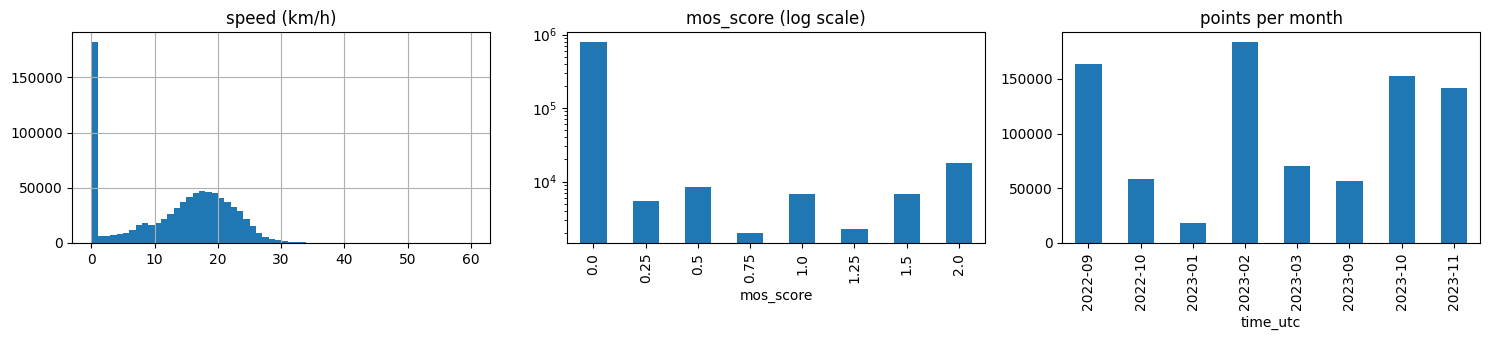

In [6]:
fig, ax = plt.subplots(1, 3, figsize=(15, 3.5))
gps.speed_kmh.clip(upper=60).hist(bins=60, ax=ax[0]); ax[0].set_title("speed (km/h)")
gps.mos_score.value_counts().sort_index().plot.bar(ax=ax[1]); ax[1].set_title("mos_score (log scale)"); ax[1].set_yscale("log")
gps.time_utc.dt.to_period("M").value_counts().sort_index().plot.bar(ax=ax[2]); ax[2].set_title("points per month")
plt.tight_layout()

**Cleaning.** We drop implausible speeds (> 45 km/h: GPS errors or a ride in a car or bus) and flag points below 2 km/h as `stopped` (waiting at lights, pushing the bike) — we keep them, because waiting may itself be stressful.

In [7]:
n0 = len(gps)
gps = gps[gps.speed_kmh < 45].copy()     # drop implausible speeds
gps["stopped"] = gps.speed_kmh < 2      # True/False column: is the cyclist (almost) standing still?
print(f"removed {n0 - len(gps):,} implausible points; {gps.stopped.mean():.0%} of remaining points are stops")

removed 63 implausible points; 22% of remaining points are stops


### ✏️ Your turn 1
Is stress more frequent when cyclists are **stopped** or **moving**?

Every row is one second of riding. `detected_mos` is 1 for a stressed second and 0 otherwise, so the **mean** of `detected_mos` is the *share* of stressed seconds. Multiply that share by 3600 (seconds per hour) to get **stress events per hour**.

Fill in the blanks: group by the column that says whether a cyclist is stopped, take the mean, multiply by 3600.

<details><summary>🆘 Hint</summary>

The column created in the cleaning step is called `stopped`. The function for the average is `.mean()`.
</details>

In [9]:
stress_per_hour = gps.groupby("____").detected_mos._____() * ____
stress_per_hour

,detected_mos
stopped,
False,57.064403
True,72.168002


In [10]:
check(lambda: set(stress_per_hour.index) == {True, False} and 0 < stress_per_hour.max() < 3600,
      ok="✅ Well done! Which group has more stress events per hour?")

✅ Well done! Which group has more stress events per hour?


> 💬 **Point for discussion:** Why could stopping go together with stress? Think of traffic lights, conflicts with cars at junctions, etc.

## 2 · From points to places: a grid of cells  

Our points describe **people**; we want to learn about **places**. We therefore aggregate all points inside the same **100 m × 100 m cell**. This smooths out GPS error and the physiological delay, turns rare events into stable rates, and gives us a common unit for attaching satellite, OSM and street view data.

Our outcome is the **stress rate** — Moments of Stress per hour of riding in a cell.


<details><summary>🔍 What the code does</summary>

`cell_id` assigns each point to a cell; `groupby("cell_id").agg(...)` computes one row per cell: seconds of riding (`n_points`), distinct rides and riders, mean stress score, stress rate, median speed and share of time stopped.
</details>

In [11]:
gps["cell_id"] = cell_id(gps.x, gps.y)            # assign each point to its grid cell (square or H3)

cells = gps.groupby("cell_id").agg(
    n_points    = ("ride_id", "size"),             # seconds of riding in the cell
    n_rides     = ("ride_id", "nunique"),          # distinct trips
    n_riders    = ("rider_id", "nunique"),         # distinct people
    mos_mean    = ("mos_score", "mean"),           # mean stress score
    stress_rate = ("detected_mos", lambda s: s.mean() * 3600),   # stress events per hour of riding (see above)
    speed_med   = ("speed_kmh", "median"),
    stop_share  = ("stopped", "mean"),             # share of time standing still
)
print(len(cells), f"cells ({CELL_LABEL}) with data")
cells.describe().round(2)

1302 cells (100 m square) with data


,n_points,n_rides,n_riders,mos_mean,stress_rate,speed_med,stop_share
count,1302.00,1302.00,1302.00,1302.00,1302.00,1302.00,1302.00
mean,648.77,34.52,7.93,0.07,54.58,15.59,0.11
std,932.93,38.70,6.02,0.07,50.16,5.86,0.20
min,1.00,1.00,1.00,0.00,0.00,0.00,0.00
25%,73.00,6.00,3.00,0.04,26.30,13.16,0.00
50%,270.00,21.00,7.00,0.06,52.94,16.95,0.00
75%,850.75,51.00,11.00,0.09,70.98,19.40,0.12
max,7811.00,253.00,26.00,1.00,600.00,33.97,1.00


### ✏️ Your turn 2
A cell visited by one rider on one day tells us more about that **person** than about the **place**.
Keep only cells with **at least 10 rides and at least 3 different riders**.

<details><summary>🆘 Hint</summary>

"At least" means `>=`. The columns are `n_rides` and `n_riders`; the thresholds are stored in `MIN_RIDES` and `MIN_RIDERS`. Both conditions must be true: `(condition 1) & (condition 2)`.
</details>

In [12]:
MIN_RIDES, MIN_RIDERS = 10, 3
cells_original = cells.copy()                      # keep a copy for comparison
cells = cells[(cells.n_rides >= _____) & (cells._____ >= MIN_RIDERS)]
print(len(cells), "reliable cells out of", len(cells_original), f"({len(cells)/len(cells_original):.0%} kept)")

859 reliable cells out of 1302 (66% kept)


In [13]:
check(lambda: len(cells) < len(cells_original) and (cells.n_rides >= 10).all() and (cells.n_riders >= 3).all())

✅ Well done!


**Stress map.** Colours use **quantiles** (each of the 5 classes holds 20 % of the cells) — check the legend for the real values. Switch to the satellite background with the layer button (top right).

In [14]:
cells_gdf = cells_to_gdf(cells)
show_map(cells_gdf, "stress_rate", cmap="Reds", scheme="quantiles", k=5,
         legend_kwds={"caption": "stress events / hour"})

> 💬 **Point for discussion:** Where do stress hotspots occur — junctions, main roads, the old town? Would the picture change with 50 m or 250 m cells (MAUP)?

## 4 · OpenStreetMap: traffic infrastructure 

**OpenStreetMap** is a free world map made by volunteers (**volunteered geographic information**). Features are points (nodes) and lines (ways) described by `key=value` **tags**:

| tag | meaning |
|---|---|
| `highway=traffic_signals` | traffic light at a junction or crossing |
| `highway=cycleway`, `cycleway=lane/track` | cycle path, or cycle lane along a road |
| `highway=primary/secondary/tertiary` | main roads — a proxy for motor traffic |
| `natural=tree` | individually mapped tree |

<details><summary>📖 Deep dive: OSM data quality</summary>

- Roads are very complete in Germany, other features less so: a cell without mapped trees may simply not have been mapped yet (**mapping bias**).
- Tagging is not always consistent (a cycle lane may be tagged on the road *or* as a separate way).
- OSM shows the **present**, while the rides are from 2022–2023.
- Reference: Haklay (2010), *Environment and Planning B* 37(4), 682–703.
</details>

<details><summary>🔍 What the code does</summary>

`ox.features_from_bbox` downloads all features with the tags in `OSM_TAGS` (via the Overpass API); we split them into **signals** and **trees** (points) and **cycle infrastructure** and **busy roads** (lines). For lines, `gpd.overlay` cuts them at the cell borders and we sum the lengths per cell.
</details>

In [15]:
OSM_TAGS = {
    "highway": ["traffic_signals", "cycleway", "primary", "secondary", "tertiary"],
    "natural": ["tree"],
    "cycleway": True, "cycleway:both": True, "cycleway:left": True, "cycleway:right": True,
}
def fetch_osm():
    import osmnx as ox
    f = ox.features_from_bbox(BBOX_WGS84, tags=OSM_TAGS).reset_index()     # bbox = (west, south, east, north)
    cols = ["element", "id", "highway", "natural", "cycleway", "cycleway:both", "cycleway:left", "cycleway:right", "geometry"]
    return f.reindex(columns=cols).to_crs(CRS)

osm = get_data("osm_features.parquet", fetch_osm, "gdf")

signals = osm[osm.highway == "traffic_signals"]
trees   = osm[osm.natural == "tree"]
lines   = osm[osm.geom_type.isin(["LineString", "MultiLineString"])]
cycle_infra = lines[(lines.highway == "cycleway") |                                   # separate cycle paths …
                    lines[["cycleway", "cycleway:both", "cycleway:left", "cycleway:right"]]
                        .isin(["lane", "track", "separate", "shared_lane"]).any(axis=1)]   # … or lanes on roads
busy_roads = lines[lines.highway.isin(["primary", "secondary", "tertiary"])]
print(f"{len(signals)} traffic signals · {len(trees)} trees · "
      f"{lines.length.sum()/1000:.0f} km in total · "
      f"{cycle_infra.length.sum()/1000:.0f} km cycle infrastructure · {busy_roads.length.sum()/1000:.0f} km busy roads")

✅ osm_features.parquet: live download OK
209 traffic signals · 2608 trees · 128 km in total · 69 km cycle infrastructure · 46 km busy roads


In [16]:
cells_gdf = cells_to_gdf(cells)
def length_per_cell(lines_gdf):
    parts = gpd.overlay(lines_gdf[["geometry"]], cells_gdf.reset_index()[["cell_id", "geometry"]],
                        how="intersection", keep_geom_type=True)        # cut lines at cell borders
    return parts.assign(length=parts.length).groupby("cell_id").length.sum()   # metres per cell

cells["cycle_m"]     = length_per_cell(cycle_infra).reindex(cells.index, fill_value=0)
cells["busy_road_m"] = length_per_cell(busy_roads).reindex(cells.index, fill_value=0)

In [17]:
def count_per_cell(points):
    # number of point features per grid cell (cells without any get 0)
    pts = points[points.geom_type == "Point"]                       # only point features
    return pd.Series(cell_id(pts.geometry.x, pts.geometry.y)).value_counts().reindex(cells.index, fill_value=0)

### ✏️ Your turn 3
Use the helper `count_per_cell(...)` (defined in the cell above) to count **traffic signals** and **trees** per cell.
The OpenStreetMap features are already split into the tables `signals`, `trees`, `cycle_infra` and `busy_roads`.

<details><summary>🆘 Hint</summary>

`count_per_cell` needs one table of points as input: `count_per_cell(name_of_the_table)`. The table names are listed above.
</details>

In [18]:
cells["n_signals"] = count_per_cell(____)
cells["n_trees"]   = count_per_cell(____)
cells[["n_signals", "n_trees", "cycle_m", "busy_road_m"]].describe().round(1)

,n_signals,n_trees,cycle_m,busy_road_m
count,859.0,859.0,859.0,859.0
mean,0.2,2.3,64.5,44.1
std,0.8,4.4,80.7,72.2
min,0.0,0.0,0.0,0.0
25%,0.0,0.0,0.0,0.0
50%,0.0,0.0,29.4,0.0
75%,0.0,3.0,106.7,90.4
max,7.0,45.0,414.5,425.6


In [19]:
check(lambda: {"n_signals", "n_trees"} <= set(cells.columns) and cells.n_signals.sum() > 0
              and not cells.n_signals.equals(cells.n_trees),
      ok="✅ Well done! Which cells have the most traffic signals?")

✅ Well done! Which cells have the most traffic signals?


## 5 · Street view: traffic lights seen by AI 

Satellites see roofs and tree tops; cyclists look **ahead** and see façades, cars, trees and sky. **Mapillary** is a crowd-sourced street view platform (images © Mapillary contributors, CC-BY-SA). We take one photo for each of the **15 calmest** and **15 most stressful** cells.

Two pre-trained deep-learning models analyse the photos:
- **Semantic segmentation** (SegFormer, trained on the Cityscapes street scenes) gives **a class for every pixel** → how much of the view is vegetation, sky, cars …
- **Object detection** (YOLO26, trained on the 80 COCO classes) draws **boxes** around individual objects such as traffic lights.

$$\text{Green View Index (GVI)} = \frac{\text{vegetation + terrain pixels}}{\text{all pixels}}$$

GVI (Li et al. 2015) measures *perceived* greenness at eye level.

<details><summary>📖 Deep dive: models and biases</summary>

| task | output | example question |
|---|---|---|
| image classification | one label per image | "Is this a residential street?" |
| object detection | boxes around objects | "How many cars are there?" |
| semantic segmentation | a class for every pixel | "How much of the view is vegetation?" |

- **SegFormer** (Xie et al. 2021) is a transformer-based segmentation network; we use the small `b0` variant (3.7 M parameters, runs on a CPU). Cityscapes (Cordts et al. 2016) contains street scenes from 50 mostly German cities — very similar to Osnabrück.
- **YOLO** ("You Only Look Once") predicts all boxes in a single pass; we use `yolo26s` at 1024 px because traffic lights are small. Each box has a **confidence**; we keep boxes with `CONF ≥ 0.35`.
- **Biases:** images exist where contributors went; different years and seasons (leafless trees!); a car camera sees the street differently than a cyclist; one image per cell is a small sample; models perform worse at night or in rain.
- References: Li et al. (2015); Xie et al. (2021); Cordts et al. (2016); Biljecki & Ito (2021).
</details>

<details><summary>🔍 What the code does</summary>

1. Take the 15 lowest and 15 highest stress cells (a contrast design that needs few images).
2. For each cell, ask the Mapillary API for images inside the cell, skip 360° panoramas and keep the most recent photo.
3. Segment every photo with SegFormer, compute the share of each class, and run YOLO26.
Without a Mapillary token, pre-downloaded images and results are used. With live processing, a GPU (*Runtime → Change runtime type → T4 GPU*) speeds things up.
</details>

In [20]:
ranked = cells.sort_values("stress_rate")
svi_cells = pd.concat([ranked.head(15).assign(group="low stress"),       # 15 calmest cells
                       ranked.tail(15).assign(group="high stress")])     # 15 most stressful cells
svi_gdf = cells_to_gdf(svi_cells)
SVI_DIR = DATA_DIR / "svi"; SVI_DIR.mkdir(exist_ok=True)

def fetch_mapillary():
    import requests
    if not MAPILLARY_TOKEN: raise RuntimeError("no Mapillary token set")
    rows = []
    for cid, geom in svi_gdf.to_crs(4326).geometry.items():
        # all images inside the cell (bbox = west,south,east,north in degrees)
        r = requests.get("https://graph.mapillary.com/images", timeout=30, params={
            "access_token": MAPILLARY_TOKEN, "bbox": ",".join(map(str, geom.bounds)), "limit": 100,
            "fields": "id,captured_at,compass_angle,is_pano,thumb_1024_url,computed_geometry,geometry"})
        r.raise_for_status()
        imgs = [i for i in r.json().get("data", []) if not i.get("is_pano")]   # skip 360° panoramas
        if not imgs: continue
        img = max(imgs, key=lambda i: i["captured_at"])            # most recent photo
        (SVI_DIR / f"{cid}.jpg").write_bytes(requests.get(img["thumb_1024_url"], timeout=30).content)
        lon, lat = (img.get("computed_geometry") or img["geometry"])["coordinates"]
        rows.append({"cell_id": cid, "image_id": img["id"], "compass_angle": img.get("compass_angle"),
                     "captured_at": pd.to_datetime(img["captured_at"], unit="ms"), "lon": lon, "lat": lat})
    meta = pd.DataFrame(rows)
    return gpd.GeoDataFrame(meta, geometry=gpd.points_from_xy(meta.lon, meta.lat), crs=4326)

svi = get_data(f"svi_images_{GRID_TYPE}.parquet", fetch_mapillary, "gdf")   # one file per grid type
svi = svi[svi.cell_id.isin(svi_cells.index) & svi.cell_id.map(lambda c: (SVI_DIR / f"{c}.jpg").exists())]
print(len(svi), "cells with a street view image")

✅ svi_images_square.parquet: live download OK
23 cells with a street view image


In [22]:
from PIL import Image
segmenter = None

# the 19 Cityscapes classes and their official colours (used for plotting)
CITYSCAPES = ["road", "sidewalk", "building", "wall", "fence", "pole", "traffic light", "traffic sign",
              "vegetation", "terrain", "sky", "person", "rider", "car", "truck", "bus", "train",
              "motorcycle", "bicycle"]
PALETTE = np.array([(128, 64, 128), (244, 35, 232), (70, 70, 70), (102, 102, 156), (190, 153, 153),
                    (153, 153, 153), (250, 170, 30), (220, 220, 0), (107, 142, 35), (152, 251, 152),
                    (70, 130, 180), (220, 20, 60), (255, 0, 0), (0, 0, 142), (0, 0, 70), (0, 60, 100),
                    (0, 80, 100), (0, 0, 230), (119, 11, 32)], dtype=np.uint8)

def segment_image(path):
    """Label map: every pixel gets the index of its Cityscapes class (255 = unlabelled)."""
    global segmenter
    if segmenter is None:   # load the model once (~15 MB from Hugging Face)
        from transformers import pipeline
        segmenter = pipeline("image-segmentation", model="nvidia/segformer-b0-finetuned-cityscapes-1024-1024")
    img = Image.open(path).convert("RGB")
    label = np.full((img.height, img.width), 255, dtype=np.uint8)
    for m in segmenter(img):                                   # one binary mask per class found
        if m["label"] in CITYSCAPES:
            label[np.array(m["mask"]) > 0] = CITYSCAPES.index(m["label"])
    return label

def segment_all():
    rows = []
    for c in svi.cell_id:
        label = segment_image(SVI_DIR / f"{c}.jpg")
        Image.fromarray(label).save(SVI_DIR / f"{c}_seg.png")                  # keep for visualisation
        rows.append({"cell_id": c, **{name: (label == k).mean() for k, name in enumerate(CITYSCAPES)}})
    return pd.DataFrame(rows)

seg = get_data(f"svi_segmentation_{GRID_TYPE}.parquet", segment_all, "df").set_index("cell_id")
for c in ["vegetation", "terrain", "sky", "road", "car", "building"]:   # classes absent from every image → 0
    if c not in seg: seg[c] = 0.0
seg["gvi"] = seg.vegetation + seg.terrain                                 # Green View Index
seg = seg.join(svi_cells[["group", "stress_rate"]], how="inner")  # add stress and NDVI of the cell
seg[["group", "gvi", "sky", "road", "car", "building"]].head()

Loading weights:   0%|          | 0/208 [00:00<?, ?it/s]

✅ svi_segmentation_square.parquet: live download OK


,group,gvi,sky,road,car,building
cell_id,,,,,,
4346_57935,low stress,0.249936,0.041099,0.074366,0.171807,0.344011
4350_57903,low stress,0.216436,0.108088,0.321987,0.030364,0.194819
4331_57906,low stress,0.391523,0.067755,0.470576,0.010939,0.009553
4331_57937,low stress,0.045251,0.253640,0.504060,0.005187,0.176900
4349_57904,low stress,0.147393,0.116530,0.212023,0.025757,0.423367


In [23]:
CONF = 0.35                     # minimum confidence for a detection to count
detector = None

def detect_all():
    global detector
    from ultralytics import YOLO
    if detector is None: detector = YOLO("yolo26s.pt")         # latest Ultralytics model, COCO classes
    rows = []
    for c in svi.cell_id:
        r = detector.predict(str(SVI_DIR / f"{c}.jpg"), conf=0.1, imgsz=1024, verbose=False)[0]
        for (x1, y1, x2, y2), k, p in zip(r.boxes.xyxy.tolist(), r.boxes.cls.tolist(), r.boxes.conf.tolist()):
            rows.append({"cell_id": c, "label": r.names[int(k)], "conf": p, "x1": x1, "y1": y1, "x2": x2, "y2": y2})
    return pd.DataFrame(rows, columns=["cell_id", "label", "conf", "x1", "y1", "x2", "y2"])

det = get_data(f"svi_detections_{GRID_TYPE}.parquet", detect_all, "df")
det = det[det.cell_id.isin(seg.index) & (det.conf >= CONF)]        # apply the confidence threshold
print(det.label.value_counts().head(8))

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
✅ svi_detections_square.parquet: live download OK
label
car              121
bicycle            7
truck              4
person             3
traffic light      3
bus                1
Name: count, dtype: int64


**Original · segmentation · detection** for the calmest and the most stressful cell (traffic lights in orange):

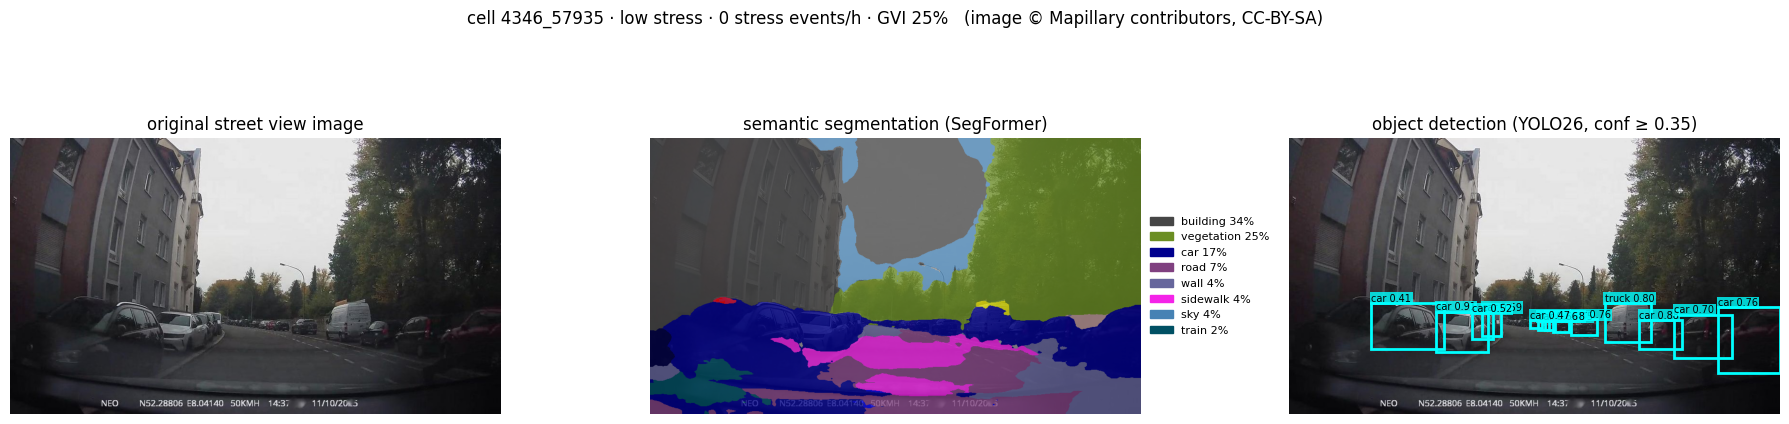

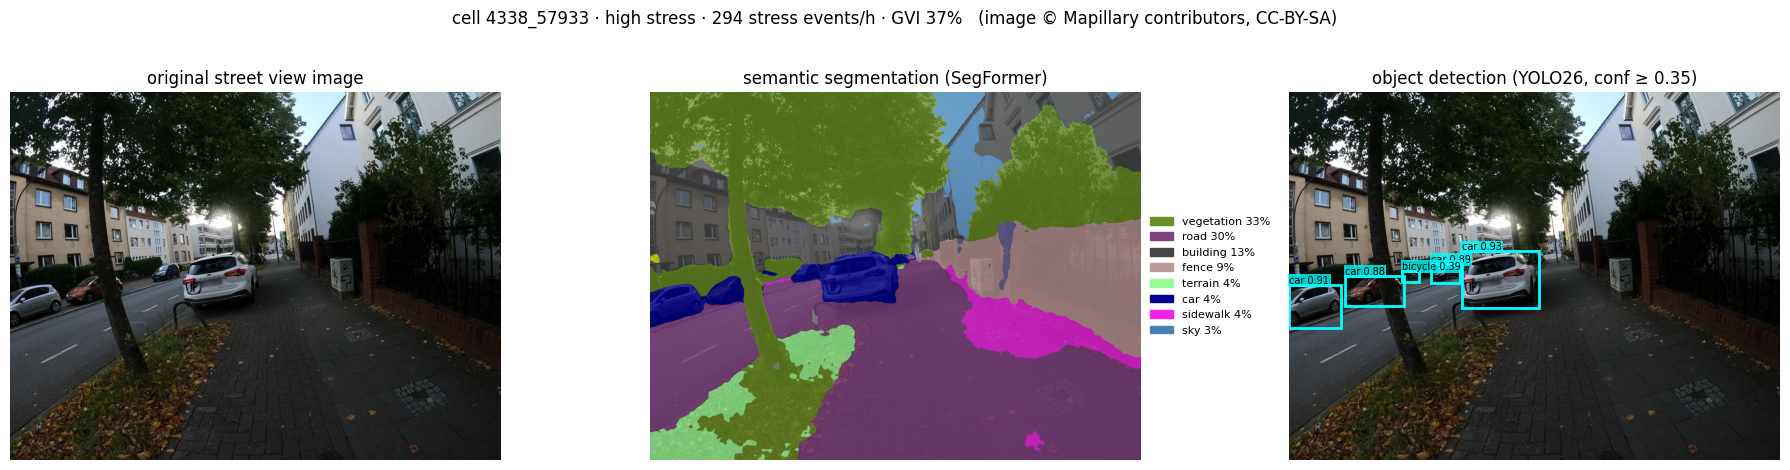

In [24]:
from matplotlib.patches import Patch, Rectangle

def show_triptych(cid):
    img = Image.open(SVI_DIR / f"{cid}.jpg").convert("RGB")
    seg_png = SVI_DIR / f"{cid}_seg.png"
    label = np.array(Image.open(seg_png)) if seg_png.exists() else segment_image(SVI_DIR / f"{cid}.jpg")
    colour = np.zeros((*label.shape, 3), dtype=np.uint8)
    colour[label < 255] = PALETTE[label[label < 255]]

    fig, ax = plt.subplots(1, 3, figsize=(18, 4.8))
    ax[0].imshow(img); ax[0].set_title("original street view image")
    ax[1].imshow(img); ax[1].imshow(colour, alpha=0.75); ax[1].set_title("semantic segmentation (SegFormer)")
    shares = pd.Series({n: (label == k).mean() for k, n in enumerate(CITYSCAPES)})
    ax[1].legend(handles=[Patch(color=PALETTE[CITYSCAPES.index(n)] / 255, label=f"{n} {v:.0%}")
                          for n, v in shares[shares > 0.01].sort_values(ascending=False).items()],
                 loc="center left", bbox_to_anchor=(1.0, 0.5), fontsize=8, frameon=False)
    ax[2].imshow(img); ax[2].set_title(f"object detection (YOLO26, conf ≥ {CONF})")
    for _, b in det[det.cell_id == cid].iterrows():
        col = "orange" if b.label == "traffic light" else "cyan"
        ax[2].add_patch(Rectangle((b.x1, b.y1), b.x2 - b.x1, b.y2 - b.y1, fill=False, color=col, lw=2))
        ax[2].text(b.x1, b.y1 - 3, f"{b.label} {b.conf:.2f}", color="black", fontsize=7,
                   bbox=dict(facecolor=col, alpha=.8, pad=1, lw=0))
    for a in ax: a.axis("off")
    fig.suptitle(f"cell {cid} · {seg.loc[cid, 'group']} · {seg.loc[cid, 'stress_rate']:.0f} stress events/h · "
                 f"GVI {seg.loc[cid, 'gvi']:.0%}   (image © Mapillary contributors, CC-BY-SA)", y=1.02)
    plt.tight_layout(); plt.show()

show_triptych(seg.stress_rate.idxmin())    # calmest cell with an image
show_triptych(seg.stress_rate.idxmax())    # most stressful cell with an image

### Do OSM and street view agree on traffic lights?
We have two independent sources for traffic lights in each street view cell:
- **OSM** (`n_signals`, from Part 4): usually **one node per junction**, however many lights stand there.
- **YOLO26 on Mapillary** (`n_lights_yolo`): the number of **light heads visible in one photo**.

Because they count different things, we compare **presence/absence** per cell — a simple form of **data validation**.

<details><summary>📖 Deep dive: why the two sources can disagree</summary>

| reason | effect |
|---|---|
| one photo shows only one direction | YOLO misses lights behind the camera → false negative |
| small, distant or hidden lights; night images | YOLO misses them → false negative |
| pedestrian lights, a neighbouring junction just outside the cell | YOLO counts lights not "in" the cell → false positive |
| OSM incomplete, or mapped just across a cell border | OSM misses lights |
| different dates (photo vs OSM edit) | lights added or removed in between |

</details>

In [25]:
yolo_lights = det[det.label == "traffic light"].groupby("cell_id").size()
cmp = pd.DataFrame({
    "n_signals_osm": cells["n_signals"].reindex(seg.index).fillna(0).astype(int),   # from Part 4
    "n_lights_yolo": yolo_lights.reindex(seg.index, fill_value=0),
    "group": seg.group,
})
cmp["osm_has"]  = cmp.n_signals_osm > 0
cmp["yolo_has"] = cmp.n_lights_yolo > 0
cmp.sort_values("n_lights_yolo", ascending=False).head(10)

,n_signals_osm,n_lights_yolo,group,osm_has,yolo_has
cell_id,,,,,
4328_57913,0,1,high stress,False,True
4365_57906,0,1,high stress,False,True
4329_57941,0,1,high stress,False,True
4331_57937,0,0,low stress,False,False
4346_57935,0,0,low stress,False,False
4350_57903,0,0,low stress,False,False
4331_57906,0,0,low stress,False,False
4332_57942,0,0,low stress,False,False
4359_57927,0,0,low stress,False,False


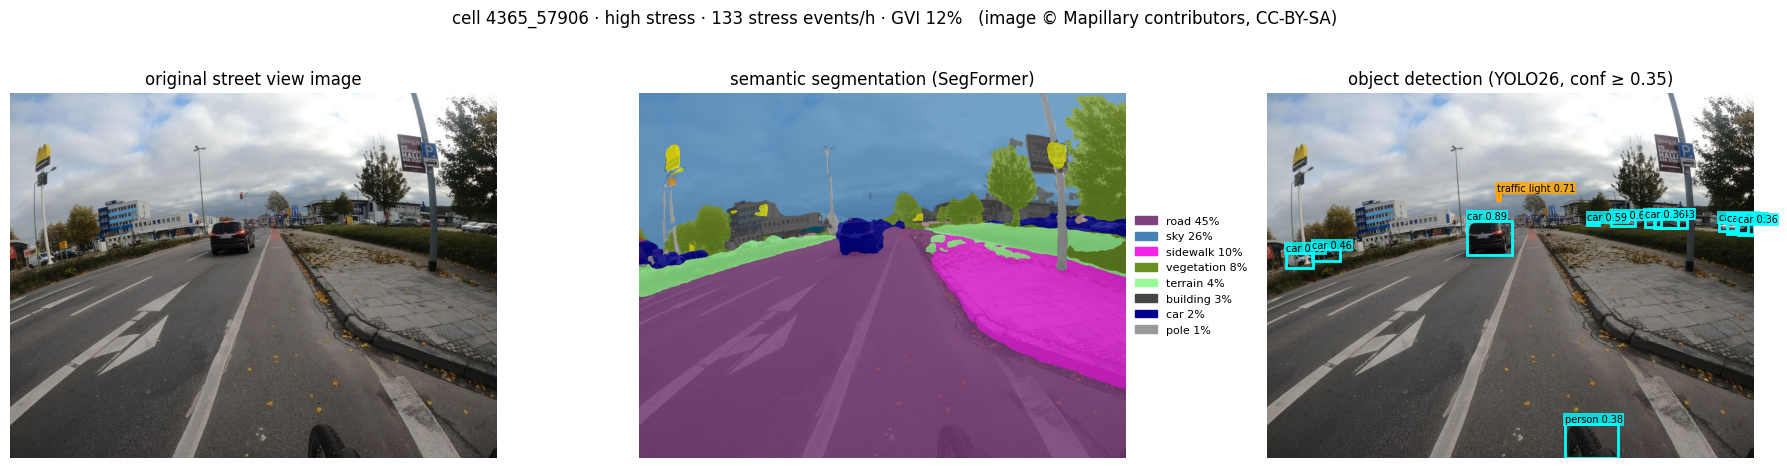

In [31]:
show_triptych(cmp.n_lights_yolo.idxmax())

### ✏️ Your turn 4
1. Make a **cross-table** of `cmp.osm_has` vs `cmp.yolo_has` with `pd.crosstab(rows, columns)`.
2. Compute the **overall agreement**: the share of cells where both columns are equal (`==`), averaged with `.mean()`.
3. Look at a disagreeing cell with `show_triptych("<cell_id>")`. Can you explain the disagreement?

In [33]:
from sklearn.metrics import cohen_kappa_score

print(pd.crosstab(cmp.____, cmp.____, rownames=["OSM: signal"], colnames=["YOLO: light"]))   # 1. cross-table
agreement = (cmp._____ == cmp.____).mean()                                                     # 2. overall agreement
print(f"overall agreement: {agreement:.0%}")
print(f"Cohen's kappa: {cohen_kappa_score(cmp.____, cmp.____):.2f}")                          # 3. kappa

disagree = cmp[cmp.osm_has != cmp.yolo_has]
print("cells where the sources disagree:", list(disagree.index))
# 4. show_triptych("...")   ← paste one of the cell IDs

YOLO: light  False  True 
OSM: signal              
False           20      3
overall agreement: 87%
Cohen's kappa: 0.00
cells where the sources disagree: ['4365_57906', '4329_57941', '4328_57913']


In [ ]:
check(lambda: 0 <= agreement <= 1, ok="✅ Well done! Which source would you trust more?")

> 💬 **Point for discussion:** Which source would you trust for counting traffic lights along a route? How could you make the street-view count more reliable (more images per cell, filtering by camera direction, using Mapillary's own detected map features)?

## 6 · Putting it together 

Which of our features go together with stress? We use **Spearman's ρ**: it correlates the *ranks* of the values, so it captures any monotonic relation ("the more A, the more B") and is robust to skewed data. ρ = +1 perfectly increasing, 0 none, −1 perfectly decreasing; roughly, |ρ| < 0.1 is negligible and |ρ| > 0.3 moderate.

**Your question:** are the infrastructure features (`n_signals`, `busy_road_m`, `cycle_m`) more strongly related to stress than greenness (`ndvi`, `n_trees`)?


,stress_rate,mos_mean
n_signals,0.13,0.21
busy_road_m,0.06,0.08
cycle_m,0.05,0.08
n_trees,0.13,0.16
stop_share,0.31,0.40
speed_med,-0.19,-0.30


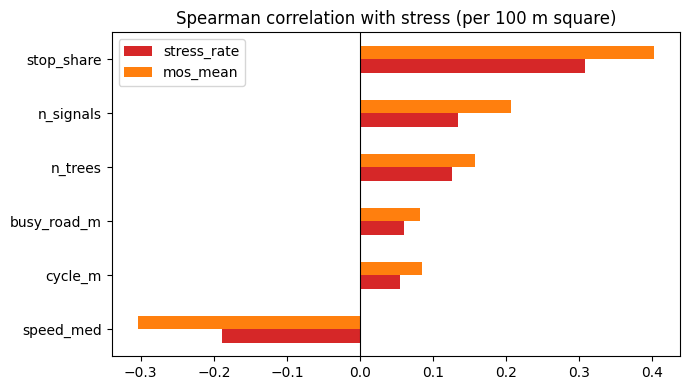

In [34]:
features = ['n_signals', 'busy_road_m', 'cycle_m', 'n_trees', 'ndvi', 'stop_share', 'speed_med']
features = [f for f in features if f in cells]   # skips columns of unfinished tasks
corr = cells[features + ["stress_rate", "mos_mean"]].corr(method="spearman")[["stress_rate", "mos_mean"]].loc[features]
corr.sort_values("stress_rate").plot.barh(figsize=(7, 4), color=["tab:red", "tab:orange"])
plt.axvline(0, color="k", lw=.8); plt.title(f"Spearman correlation with stress (per {CELL_LABEL})"); plt.tight_layout()
corr.round(2)

The enriched grid — hover over a cell to see its values. Change `"n_signals"` to `"stress_rate"` to compare the patterns.

In [35]:
show_map(cells_to_gdf(cells), "n_signals", cmap="Reds",
         tooltip=[c for c in ["stress_rate"] + ['n_signals', 'busy_road_m', 'cycle_m', 'n_trees', 'ndvi', 'stop_share', 'speed_med'] if c in cells])

## 7 · Calm routing 

Can our results help cyclists choose a better route? A street network is a **graph**: intersections are **nodes**, street segments are **edges** with a **cost**. **Dijkstra's algorithm** finds the path with the lowest total cost between two points. The algorithm never changes — only the **edge cost** does:

| route | edge cost |
|---|---|
| 🔵 Shortest | `length` |
| 🟢 Calmest | `length × (1 + weight × penalty)` |

<details><summary>🔍 What the code does</summary>

1. Download the cycling street network with `osmnx` (or load the saved copy) and project it to metres.
2. Copy `stress_rate` from the grid cells to the street segments; `scale01` rescales values to 0–1.
3. Compute the **penalty** of every segment and the cost `rq_cost`; `add_costs(weight)` rebuilds the routable graph.
4. `compare_routes()` runs `nx.shortest_path` for both costs and reports length, detour and the share of busy roads, the number of signals passed and the mean stress rate along each route.
</details>

In [36]:
import osmnx as ox, networkx as nx
from shapely.geometry import Point, LineString

GRAPH_FILE = DATA_DIR / "osm_bike_graph.graphml"

def load_street_graph():
    # live download with fallback to the saved copy (same idea as get_data)
    if LIVE or not GRAPH_FILE.exists():
        try:
            G = ox.graph_from_bbox(bbox=BBOX_WGS84, network_type="bike", simplify=True)
            ox.save_graphml(G, GRAPH_FILE)
            print("✅ street network: live download OK"); return G
        except Exception as e:
            print(f"⚠️ street network: live download failed ({type(e).__name__}) → fallback")
    G = ox.load_graphml(GRAPH_FILE); print("📦 street network: loaded fallback"); return G

G = ox.project_graph(load_street_graph(), to_crs=CRS)
nodes, edges = ox.graph_to_gdfs(G)

# every street segment takes the values of the grid cell its centre point lies in
JOIN_COLS = [c for c in ['stress_rate', 'ndvi'] if c in cells]
centres = gpd.GeoDataFrame(geometry=edges.geometry.centroid, crs=CRS)
joined = gpd.sjoin(centres, cells_to_gdf(cells)[JOIN_COLS + ["geometry"]], how="left", predicate="within")
for col in JOIN_COLS:
    edges[col] = joined[col].reindex(edges.index).fillna(cells[col].mean())   # outside reliable cells → mean

def scale01(s):
    """Rescale to 0–1 (5th percentile → 0, 95th percentile → 1)."""
    lo, hi = s.quantile(.05), s.quantile(.95)
    return ((s - lo) / (hi - lo)).clip(0, 1)

hw = edges["highway"].astype(str)                                       # OSM road type of each segment
edges["busy"] = hw.str.contains("primary|secondary|tertiary").astype(float)
edges["cycleway"] = hw.str.contains("cycleway").astype(float)
node_hw = nodes["highway"].astype(str) if "highway" in nodes else pd.Series("", index=nodes.index)
SIGNAL_NODES = set(nodes.index[node_hw.str.contains("traffic_signals")])
edges["signal"] = [float(v in SIGNAL_NODES) for v in edges.index.get_level_values(1)]   # signal at the end
edges["penalty"] = ((0.4 * edges["busy"] + 0.3 * edges["signal"] + 0.3 * scale01(edges["stress_rate"]))
                    * (1 - 0.5 * edges["cycleway"]))                      # 0 = calm, 1 = busy & stressful
print(f"{len(SIGNAL_NODES)} signalised intersections · {edges.busy.mean():.0%} of segments on busy roads")

def add_costs(weight=1.0):
    # cost = length × (1 + weight × penalty): with weight 0 every route is the shortest one
    edges["rq_cost"] = edges["length"] * (1.0 + weight * edges["penalty"])
    return ox.graph_from_gdfs(nodes, edges)

G_weighted = add_costs()
print(f"{len(nodes):,} intersections · {len(edges):,} street segments · mean penalty {edges.penalty.mean():.2f}")

✅ street network: live download OK
81 signalised intersections · 9% of segments on busy roads
5,251 intersections · 12,373 street segments · mean penalty 0.20


In [41]:
SUMMARY_COLS = ['stress_rate', 'signal']

ORIG_XY = (433200, 5791200)    # south-west of the centre (EPSG:25832, metres)
DEST_XY = (436100, 5793000)    # north-east of the centre
ROUTES = {"Shortest": ("length", "blue"), "Calmest": ("rq_cost", "green")}

def edge_used(graph, u, v, weight):
    return min(graph[u][v].values(), key=lambda d: d[weight])        # cheapest of parallel edges

def compare_routes(graph, orig_xy=ORIG_XY, dest_xy=DEST_XY):
    o = ox.nearest_nodes(graph, X=orig_xy[0], Y=orig_xy[1])
    d = ox.nearest_nodes(graph, X=dest_xy[0], Y=dest_xy[1])
    rows, lines = [], []
    for name, (weight, colour) in ROUTES.items():
        path = nx.shortest_path(graph, o, d, weight=weight)           # Dijkstra
        segs = [edge_used(graph, u, v, weight) for u, v in zip(path[:-1], path[1:])]
        length = sum(s["length"] for s in segs)
        row = {"route": name, "length_km": length / 1000}
        for col in SUMMARY_COLS:                                       # length-weighted mean along the route
            row[col] = sum(s["length"] * s[col] for s in segs) / length
        row["busy_road_%"] = 100 * sum(s["length"] * s["busy"] for s in segs) / length
        row["signals_passed"] = sum(n in SIGNAL_NODES for n in path)
        rows.append(row)
        pts = [Point(graph.nodes[n]["x"], graph.nodes[n]["y"]) for n in path]
        lines.append({"Route": name, "Distance": f"{length/1000:.2f} km", "geometry": LineString(pts)})
    table = pd.DataFrame(rows).set_index("route")
    table["detour_%"] = (table.length_km / table.loc["Shortest", "length_km"] - 1) * 100
    m = gpd.GeoDataFrame(lines, crs=CRS).explore(column="Route", cmap=[c for _, c in ROUTES.values()],
                                                 categories=list(ROUTES), tiles=BASEMAP,
                                                 style_kwds=dict(weight=5), tooltip=["Route", "Distance"])
    folium.TileLayer(xyz.Esri.WorldImagery, name="Satellite (Esri)", overlay=False).add_to(m)
    folium.LayerControl().add_to(m)
    display(table.round(2))
    return m

compare_routes(G_weighted)

,length_km,stress_rate,signal,busy_road_%,signals_passed,detour_%
route,,,,,,
Shortest,3.83,56.94,0.12,77.87,4,0.00
Calmest,4.19,48.02,0.02,8.96,3,9.32


### ✏️ Your turn 5
With `weight = 1` the calmest route may be identical to (or only slightly different from) the shortest one.
**Increase the weight** (try `3`, then `10`) and compare again. How much detour (%) would *you* accept for fewer busy roads and traffic lights?

<details><summary>🆘 Hint</summary>

Write a number instead of `____`, e.g. `3`. Larger weight = busy, signalised and stressful streets look "longer" to the algorithm.
</details>

In [43]:
G_weighted = add_costs(weight=___)
compare_routes(G_weighted)

,length_km,stress_rate,signal,busy_road_%,signals_passed,detour_%
route,,,,,,
Shortest,3.83,56.94,0.12,77.87,4,0.00
Calmest,4.19,48.02,0.02,8.96,3,9.32


> 💬 **Point for discussion:** Does the calm route really avoid stress hotspots — or only busy roads? Waiting at traffic lights may itself be stressful: should signals count more or less?

### ⭐ Bonus task B: does the camera look where the cyclist looks?
Mapillary gives each image a `compass_angle` (0° = north). Compute the dominant riding direction per cell and check how many images face along the riding axis (±45°, either direction).


In [44]:
def circ_mean(deg):
    # circular mean of angles in degrees
    r = np.deg2rad(deg); return np.rad2deg(np.arctan2(np.sin(r).mean(), np.cos(r).mean())) % 360

ride_dir = gps[~gps.stopped].groupby("cell_id").bearing.apply(circ_mean)     # dominant riding direction per cell
d = (svi.set_index("cell_id").compass_angle - ride_dir.reindex(svi.cell_id).values).abs() % 180
diff = np.minimum(d, 180 - d)                   # 0° = camera looks along the riding axis, 90° = across it

# ✏️ share of images that face along the riding axis (within ±45°):
print(f"{(diff <= ____).mean():.0%} of images face along the riding axis (±45°)")

83% of images face along the riding axis (±45°)


### 📚 References
- Biljecki, F. & Ito, K. (2021). Street view imagery in urban analytics and GIS: A review. *Landscape and Urban Planning* 215, 104217.
- Cordts, M. et al. (2016). The Cityscapes Dataset for Semantic Urban Scene Understanding. *CVPR*.
- Getis, A. & Ord, J. K. (1992). The analysis of spatial association by use of distance statistics. *Geographical Analysis* 24(3), 189–206.
- Haklay, M. (2010). How good is volunteered geographical information? *Environment and Planning B* 37(4), 682–703.
- Jocher, G., Qiu, J. & Chaurasia, A. (2026). *Ultralytics YOLO26.* https://docs.ultralytics.com/models/yolo26
- Kyriakou, K., Resch, B. et al. (2019). Detecting Moments of Stress from Measurements of Wearable Physiological Sensors. *Sensors* 19(17), 3805.
- Li, X. et al. (2015). Assessing street-level urban greenery using Google Street View and a modified green view index. *Urban Forestry & Urban Greening* 14(3), 675–685.
- Lin, T.-Y. et al. (2014). Microsoft COCO: Common Objects in Context. *ECCV*.
- Openshaw, S. (1984). *The Modifiable Areal Unit Problem.* CATMOG 38.
- Redmon, J. et al. (2016). You Only Look Once: Unified, Real-Time Object Detection. *CVPR*.
- Tobler, W. (1970). A computer movie simulating urban growth in the Detroit region. *Economic Geography* 46, 234–240.
- Tucker, C. J. (1979). Red and photographic infrared linear combinations for monitoring vegetation. *Remote Sensing of Environment* 8, 127–150.
- Voogt, J. A. & Oke, T. R. (2003). Thermal remote sensing of urban climates. *Remote Sensing of Environment* 86, 370–384.
- Xie, E. et al. (2021). SegFormer: Simple and Efficient Design for Semantic Segmentation with Transformers. *NeurIPS*.
- Zha, Y., Gao, J. & Ni, S. (2003). Use of normalized difference built-up index in automatically mapping urban areas from TM imagery. *International Journal of Remote Sensing* 24(3), 583–594.

*Data: Sentinel-2 © Copernicus/ESA; Landsat courtesy of USGS; © OpenStreetMap contributors (ODbL); street view images © Mapillary contributors (CC-BY-SA).*